<a href="https://colab.research.google.com/github/cj25-shree/stats-descriptives-dispersion-/blob/main/34.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# import libraries
import matplotlib.pyplot as plt
import numpy as np

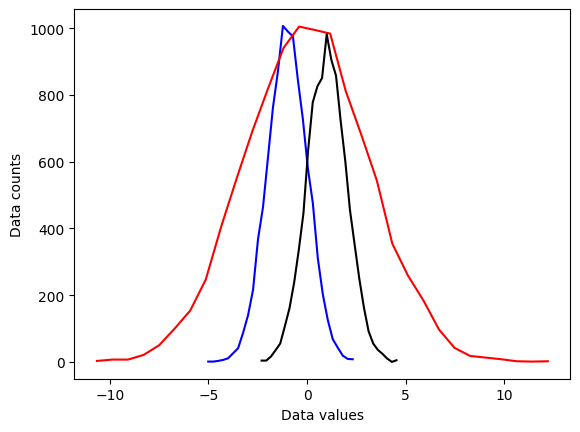

In [ ]:
## create some data distributions

# the distributions
N = 10001   # number of data points
nbins = 30  # number of histogram bins

d1 = np.random.randn(N) - 1
d2 = 3*np.random.randn(N)
d3 = np.random.randn(N) + 1

# need their histograms
y1,x1 = np.histogram(d1,nbins)
x1 = (x1[1:]+x1[:-1])/2

y2,x2 = np.histogram(d2,nbins)
x2 = (x2[1:]+x2[:-1])/2

y3,x3 = np.histogram(d3,nbins)
x3 = (x3[1:]+x3[:-1])/2


# plot them
plt.plot(x1,y1,'b')
plt.plot(x2,y2,'r')
plt.plot(x3,y3,'k')

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

In [ ]:
# side note:

meanval = 10.2
stdval  = 7.5
numsamp = 123

# this
np.random.normal(meanval,stdval,numsamp)

# is equivalent to
np.random.randn(numsamp)*stdval + meanval

array([ 4.23854548,  9.49389639,  9.51183298, 16.90494762, 28.05674618,
       23.35391148,  1.48489929,  8.91909116,  6.74635158, 13.25544059,
       23.48444364, 16.00590613, 20.88326389, 14.24461895, 13.68957937,
       13.9368822 , 17.61668602, 10.93150501,  9.8946126 , 15.81947381,
        8.3338039 , 12.29434716, 15.6083704 , 21.57581338, -7.74262713,
       10.37943543,  5.81706415,  6.17105714,  3.61419265, 13.61711653,
        8.79334595, 18.57990045,  4.66088108,  5.28525678, 12.72454595,
        6.95940535,  9.35375374, 14.38061255, 15.29564561, 13.48471124,
        9.64620007,  4.02956299,  3.21789516, 23.62062775, -0.98535149,
       24.11063233, 18.79152231, 15.6339214 ,  9.94929535, 18.58765525,
       11.42541769,  5.39417963, 12.64306069, -0.69048179, 13.72926639,
       12.47764015,  3.68189443,  5.40343314,  5.92567199,  1.06497985,
        2.17964239,  5.10423982,  5.35900028, 19.09105487,  9.0670058 ,
       16.58212381,  8.94868751, 18.20077123, 16.45238262, 13.78

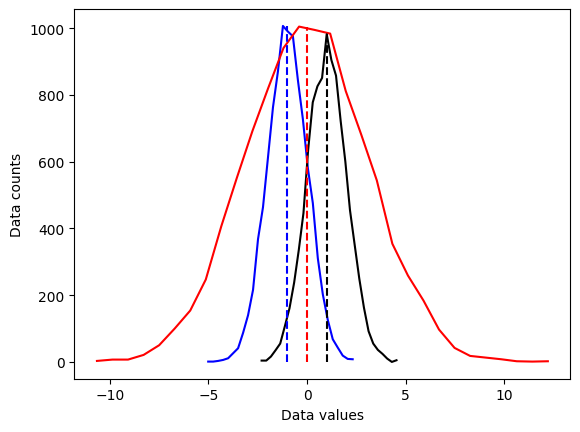

In [ ]:
## overlay the mean

# compute the means
mean_d1 = sum(d1) / len(d1)
mean_d2 = np.mean(d2)
mean_d3 = np.mean(d3)

# plot them
plt.plot(x1,y1,'b', x2,y2,'r', x3,y3,'k')
plt.plot([mean_d1,mean_d1],[0,max(y1)],'b--')
plt.plot([mean_d2,mean_d2],[0,max(y2)],'r--')
plt.plot([mean_d3,mean_d3],[0,max(y3)],'k--')

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

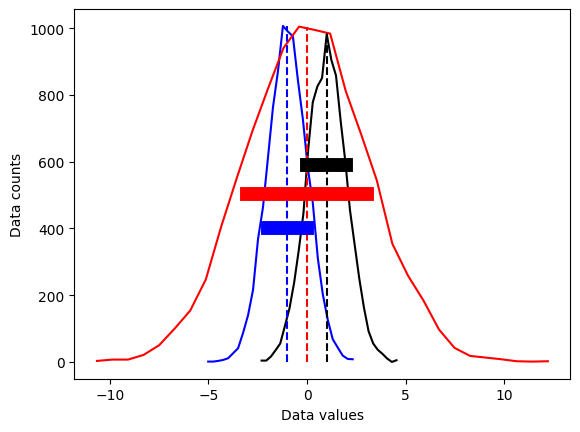

In [ ]:
## now for the standard deviation

# initialize
stds = np.zeros(3)

# compute standard deviations
stds[0] = np.std(d1,ddof=1)
stds[1] = np.std(d2,ddof=1)
stds[2] = np.std(d3,ddof=1)


# same plot as earlier
plt.plot(x1,y1,'b', x2,y2,'r', x3,y3,'k')
plt.plot([mean_d1,mean_d1],[0,max(y1)],'b--', [mean_d2,mean_d2],[0,max(y2)],'r--',[mean_d3,mean_d3],[0,max(y3)],'k--')

# now add stds
plt.plot([mean_d1-stds[0],mean_d1+stds[0]],[.4*max(y1),.4*max(y1)],'b',linewidth=10)
plt.plot([mean_d2-stds[1],mean_d2+stds[1]],[.5*max(y2),.5*max(y2)],'r',linewidth=10)
plt.plot([mean_d3-stds[2],mean_d3+stds[2]],[.6*max(y3),.6*max(y3)],'k',linewidth=10)

plt.xlabel('Data values')
plt.ylabel('Data counts')
plt.show()

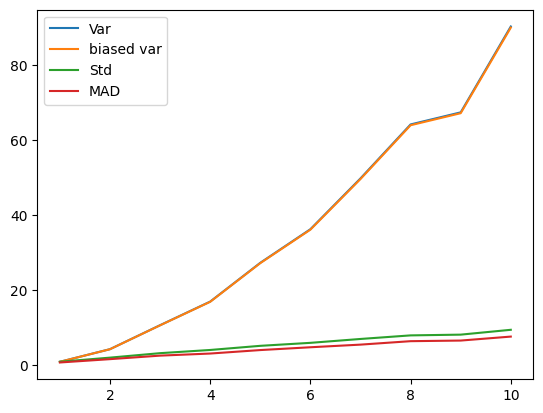

In [ ]:
## different variance measures

variances = np.arange(1,11)
N = 300

varmeasures = np.zeros((4,len(variances)))

for i in range(len(variances)):

    # create data and mean-center
    data = np.random.randn(N) * variances[i]
    datacent = data - np.mean(data)

    # variance
    varmeasures[0,i] = sum(datacent**2) / (N-1)

    # "biased" variance
    varmeasures[1,i] = sum(datacent**2) / N

    # standard deviation
    varmeasures[2,i] = np.sqrt( sum(datacent**2) / (N-1) )

    # MAD (mean absolute difference)
    varmeasures[3,i] = sum(abs(datacent)) / (N-1)


# show them!
plt.plot(variances,varmeasures.T)
plt.legend(('Var','biased var','Std','MAD'))
plt.show()

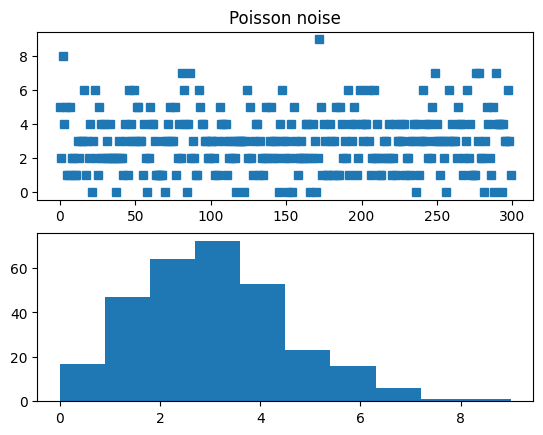

In [ ]:
## Fano factor and coefficient of variation (CV)

# need positive-valued data (why?)
data = np.random.poisson(3,300)  # "Poisson noise"

fig,ax = plt.subplots(2,1)
ax[0].plot(data,'s')
ax[0].set_title('Poisson noise')

ax[1].hist(data)
plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\l'
<>:24: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_572/1438735570.py:24: SyntaxWarning: invalid escape sequence '\l'
  plt.xlabel('$\lambda$')


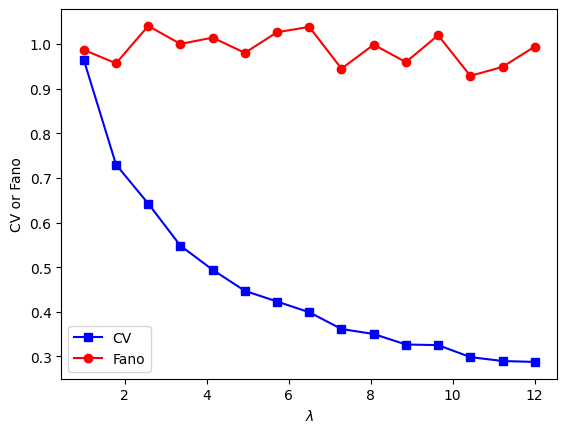

In [ ]:
## compute fano factor and CV for a range of lambda parameters

# list of parameters
lambdas = np.linspace(1,12,15)

# initialize output vectors
fano = np.zeros(len(lambdas))
cv   = np.zeros(len(lambdas))

for li in range(len(lambdas)):

    # generate new data
    data = np.random.poisson(lambdas[li],1000)

    # compute the metrics
    cv[li]   = np.std(data) / np.mean(data) # need ddof=1 here?
    fano[li] = np.var(data) / np.mean(data)


# and plot
plt.plot(lambdas,cv,'bs-')
plt.plot(lambdas,fano,'ro-')
plt.legend(('CV','Fano'))
plt.xlabel('$\lambda$')
plt.ylabel('CV or Fano')
plt.show()